# Study 2: development and mitigation strategy audit

- This notebook tests how development targets, mitigation capacity, and affordability interact under the current environment and reward rules.
- Gross emissions remain `8 + 0.10 × EDI + 0.001 × EDI²`.
- The baseline uses persistence 0.80, spillover 0.20, failure threshold 100, and 200 steps.

## 1. Shared settings and policies

- The development-then-mitigation policies develop to EDI 40, 60, or 80, then choose either medium or high mitigation. If the intended action is unaffordable, it falls back to Save for that step.
- The adaptive rule begins mitigating when the observed EDI bin reaches 2 (EDI at least 67), then selects low, medium, or high mitigation from the observed local pollution bin. It uses the same three bins as the environment, so this is an approximate switch rather than an exact EDI target.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

from study_2_economic_sustainability.config import EnvironmentConfig
from study_2_economic_sustainability.environment import EconomicSustainabilityEnvironment

In [10]:
SEEDS = tuple(range(10_000, 10_100))
TARGETS = (40, 60, 80)
PERSISTENCE_BASELINE = 0.80
PERSISTENCE_FOLLOW_UP = 0.90
CAPACITIES = (16, 20, 30)
HIGH_COSTS = (25, 50)
ACTION_NAMES = ("save", "develop", "low", "medium", "high")
base_config = EnvironmentConfig()
base_config.persistence == PERSISTENCE_BASELINE
base_config.spillover == 0.20
base_config.failure_threshold == 100.0
base_config.episode_steps == 200

100 shared evaluation seeds; 8 policies
High-capacity and cost combinations: 6


In [ ]:
POLICIES = []

for target in TARGETS:
    for mode in ("medium", "high"):
        policy_name = f"target_{target}_{mode}"
        policy_details = {"kind": "target", "target": target, "mode": mode}
        POLICIES.append((policy_name, policy_details))

POLICIES.append(("threshold_reference", {"kind": "threshold"}))
POLICIES.append(("adaptive_after_67", {"kind": "adaptive"}))

POLICY_ORDER = []
POLICY_DETAILS = {}
for policy_name, policy_details in POLICIES:
    POLICY_ORDER.append(policy_name)
    POLICY_DETAILS[policy_name] = policy_details
print(f"{len(SEEDS)} shared evaluation seeds; {len(POLICY_ORDER)} policies")
print(f"High-capacity and cost combinations: {len(CAPACITIES) * len(HIGH_COSTS)}")

## 2. Choose an intended action and apply the affordability fallback

In [11]:
def intended_action(policy_name, observation, environment, region):
    details = POLICY_DETAILS[policy_name]

    if details["kind"] == "target":
        edi = environment.development_indices[region]
        if edi < details["target"]:
            return 1
        return 3 if details["mode"] == "medium" else 4

    if details["kind"] == "threshold":
        edi = environment.development_indices[region]
        pollution = environment.pollution_loads[region]
        if edi < 70:
            return 1
        if pollution >= 35:
            return 4
        if pollution >= 25:
            return 3
        if pollution >= 15:
            return 2
        return 0

    edi_bin, currency_bin, pollution_bin, global_bin = observation
    if edi_bin < 2:
        return 1
    return (2, 3, 4)[pollution_bin]

In [ ]:
def prepare_actions(policy_name, observations, environment):
    proposed = []
    executed = []
    fallback_count = 0

    for region in range(4):
        observation = observations[region]
        desired = intended_action(policy_name, observation, environment, region)
        balance = environment.currency_balances[region]
        cost = environment.config.action_costs[desired]
        actual = desired if balance >= cost else 0
        fallback_count += actual != desired
        proposed.append(desired)
        executed.append(actual)

    return proposed, executed, fallback_count

In [ ]:
def make_config(persistence, capacity, high_cost):
    config = EnvironmentConfig()
    config.persistence = persistence
    config.mitigation_capacity = (*config.mitigation_capacity[:4], capacity)
    config.action_costs = (*config.action_costs[:4], high_cost)
    return config

## 3. Run one policy episode and record what happened

- `mitigation_success_rate` is the share of intended mitigation attempts that executed as mitigation. `emissions_prevented` and `remaining_emissions` are summed from the environment's reported values.
- Income, spending, and end-of-step currency are recorded by region and step for the trajectory plots.

In [ ]:
def create_episode_totals():
    return {
        "pollution_values": [],
        "proposed_counts": [0] * 5,
        "executed_counts": [0] * 5,
        "fallback_count": 0,
        "mitigation_attempts": 0,
        "mitigation_executed": 0,
        "income_covers_selected_cost": 0,
        "emissions_prevented": 0.0,
        "remaining_emissions": 0.0,
        "gross_emissions": 0.0,
        "incoming_spillover": 0.0,
        "total_income": 0.0,
        "total_spending": 0.0,
    }


In [ ]:
def record_episode_step(totals, proposed_actions, executed_actions, info, config):
    totals["pollution_values"].extend(info["pollution_loads"])
    totals["total_income"] += sum(info["income"])
    totals["total_spending"] += sum(info["costs_paid"])
    totals["emissions_prevented"] += sum(info["emissions_avoided"])
    totals["remaining_emissions"] += sum(info["remaining_emissions"])
    totals["gross_emissions"] += sum(info["gross_emissions"])
    totals["incoming_spillover"] += sum(info["incoming_spillover"])

    for region in range(4):
        proposed_action = proposed_actions[region]
        executed_action = executed_actions[region]
        totals["proposed_counts"][proposed_action] += 1
        totals["executed_counts"][executed_action] += 1

        if proposed_action in (2, 3, 4):
            totals["mitigation_attempts"] += 1
            if executed_action in (2, 3, 4):
                totals["mitigation_executed"] += 1
            if info["income"][region] >= config.action_costs[proposed_action]:
                totals["income_covers_selected_cost"] += 1


In [ ]:
def make_trace_row(policy_name, seed, persistence, capacity, high_cost, step, info):
    return {
        "policy": policy_name,
        "seed": seed,
        "persistence": persistence,
        "capacity": capacity,
        "high_cost": high_cost,
        "step": step,
        "income": sum(info["income"]) / 4,
        "spending": sum(info["costs_paid"]) / 4,
        "currency": sum(info["currency_balances"]) / 4,
        "pollution": sum(info["pollution_loads"]) / 4,
    }


In [ ]:
def add_action_fractions(row, totals, episode_region_steps):
    for action, count in enumerate(totals["proposed_counts"]):
        action_name = ACTION_NAMES[action]
        row[f"proposed_{action_name}_fraction"] = count / episode_region_steps

    for action, count in enumerate(totals["executed_counts"]):
        action_name = ACTION_NAMES[action]
        row[f"executed_{action_name}_fraction"] = count / episode_region_steps

    return row


In [ ]:
def make_episode_outcomes(environment, totals, persistence, capacity, high_cost, failed):
    pollution_values = totals["pollution_values"]
    episode_region_steps = 4 * environment.step_count

    return {
        "persistence": persistence,
        "capacity": capacity,
        "high_cost": high_cost,
        "steps": environment.step_count,
        "failed": failed,
        "final_mean_edi": sum(environment.development_indices) / 4,
        "final_mean_pollution": sum(environment.pollution_loads) / 4,
        "mean_pollution": sum(pollution_values) / len(pollution_values),
        "max_pollution": max(pollution_values),
        "final_mean_currency": sum(environment.currency_balances) / 4,
        "total_income": totals["total_income"],
        "total_spending": totals["total_spending"],
        "emissions_prevented": totals["emissions_prevented"],
        "remaining_emissions": totals["remaining_emissions"],
        "gross_emissions": totals["gross_emissions"],
        "mean_incoming_spillover": totals["incoming_spillover"] / episode_region_steps,
        "fallback_count": totals["fallback_count"],
    }


In [ ]:
def add_mitigation_metrics(row, totals, reached_target, policy_details):
    mitigation_attempts = totals["mitigation_attempts"]
    mitigation_executed = totals["mitigation_executed"]
    row["mitigation_attempts"] = mitigation_attempts
    row["mitigation_executed"] = mitigation_executed
    row["mitigation_success_rate"] = 1.0
    row["income_covers_selected_cost_fraction"] = 0.0

    if mitigation_attempts:
        row["mitigation_success_rate"] = mitigation_executed / mitigation_attempts
        row["income_covers_selected_cost_fraction"] = (
            totals["income_covers_selected_cost"] / mitigation_attempts
        )

    row["reached_target"] = None
    if policy_details["kind"] == "target":
        row["reached_target"] = reached_target is not None
    row["target_reached_step"] = reached_target
    return row


In [ ]:
def make_episode_summary(
    policy_name, seed, persistence, capacity, high_cost,
    environment, totals, failed, reached_target, policy_details
):
    row = {
        "policy": policy_name,
        "seed": seed,
    }
    row.update(
        make_episode_outcomes(
            environment, totals, persistence, capacity, high_cost, failed
        )
    )
    row = add_mitigation_metrics(row, totals, reached_target, policy_details)
    return add_action_fractions(row, totals, 4 * environment.step_count)


In [ ]:
def add_trace_if_requested(
    trace, keep_trace, policy_name, seed, persistence, capacity, high_cost,
    environment, info
):
    if keep_trace:
        trace.append(
            make_trace_row(
                policy_name, seed, persistence, capacity, high_cost,
                environment.step_count, info
            )
        )


In [ ]:
def check_target_reached(policy_details, reached_target, terminated, environment):
    if policy_details["kind"] == "target" and reached_target is None and not terminated:
        if min(environment.development_indices) >= policy_details["target"]:
            return environment.step_count
    return reached_target


In [ ]:
def run_policy_episode(policy_name, seed, persistence=0.80, capacity=30, high_cost=50, keep_trace=False):
    config = make_config(persistence, capacity, high_cost)
    environment = EconomicSustainabilityEnvironment(config=config)
    observations = environment.reset(seed)

    totals = create_episode_totals()
    trace = []
    reached_target = None
    policy_details = POLICY_DETAILS[policy_name]

    while True:
        proposed_actions, executed_actions, fallback_count = prepare_actions(
            policy_name, observations, environment
        )
        totals["fallback_count"] += fallback_count

        result = environment.step(executed_actions)
        observations, rewards, terminated, truncated, info = result
        record_episode_step(totals, proposed_actions, executed_actions, info, config)

        add_trace_if_requested(
            trace, keep_trace, policy_name, seed, persistence,
            capacity, high_cost, environment, info
        )

        reached_target = check_target_reached(policy_details, reached_target, terminated, environment)

        if terminated or truncated:
            break

    row = make_episode_summary(
        policy_name, seed, persistence, capacity, high_cost,
        environment, totals, terminated, reached_target, policy_details
    )
    return row, trace


## 4. Development targets under the current mitigation settings

- First compare all development targets at persistence 0.80, high capacity 30, and high cost 50. This isolates the policy's target and mitigation choice under the current configuration.

In [19]:
BASELINE_POLICIES = POLICY_ORDER
baseline_rows = []
baseline_trace = []
for policy in BASELINE_POLICIES:
    for seed in SEEDS:
        row, trace = run_policy_episode(policy, seed, keep_trace=True)
        baseline_rows.append(row)
        baseline_trace.extend(trace)
baseline_episodes = pd.DataFrame(baseline_rows)

In [20]:
def summarize_episodes(episodes, groups):
    metrics = ["failed", "steps", "final_mean_edi", "mean_pollution", "max_pollution", "final_mean_currency", "total_income", "total_spending", "emissions_prevented", "remaining_emissions", "fallback_count", "mitigation_success_rate", "income_covers_selected_cost_fraction"]
    summary = episodes.groupby(groups)[metrics].agg(["mean", "std"]).round(2)
    return summary.rename(columns={"failed": "failure_rate"})

display(summarize_episodes(baseline_episodes, ["policy"]))

failure_rate         steps        final_mean_edi        \
                            mean   std    mean    std           mean   std   
policy                                                                       
adaptive_after_67           0.67  0.47   74.98  88.20          64.21  5.38   
target_40_high              0.00  0.00  200.00   0.00          40.00  0.00   
target_40_medium            0.00  0.00  200.00   0.00          40.00  0.00   
target_60_high              0.01  0.10  198.14  18.60          59.95  0.50   
target_60_medium            0.01  0.10  198.14  18.60          59.95  0.50   
target_80_high              1.00  0.00   11.24   0.53          61.08  4.93   
target_80_medium            1.00  0.00   11.24   0.53          61.08  4.93   
threshold_reference         0.63  0.49   82.45  90.56          64.51  5.50   

                    mean_pollution        max_pollution        ...  \
                              mean    std          mean   std  ...   
policy                                                         ...   
adaptive_after_67            54.59  12.28        100.62  2.40  ...   
target_40_high               18.04   1.21         52.97  4.88  ...   
target_40_medium              1.98   0.35         51.47  3.78  ...   
target_60_high                5.84   5.48         86.54  5.12  ...   
target_60_medium             22.46   3.89         87.49  5.03  ...   
target_80_high               61.43   1.75        104.24  1.97  ...   
target_80_medium             61.43   1.75        104.24  1.97  ...   
threshold_reference          53.10  12.79        100.41  2.49  ...   

                    emissions_prevented          remaining_emissions           \
                                   mean      std                mean      std   
policy                                                                          
adaptive_after_67               3781.06  5300.10             1868.05  1731.88   
target_40_high                  8726.17   146.11             2081.92   139.40   
target_40_medium               10604.60    51.30              203.49    39.77   
target_60_high                 13150.02  1324.47              582.75   101.84   
target_60_medium               11209.80  1128.99             2522.97   206.48   
target_80_high                     0.00     0.00              596.10    28.20   
target_80_medium                   0.00     0.00              596.10    28.20   
threshold_reference             4261.20  5476.92             1981.14  1740.04   

                    fallback_count        mitigation_success_rate        \
                              mean    std                    mean   std   
policy                                                                    
adaptive_after_67            14.08   6.28                    1.00  0.00   
target_40_high              142.37  10.74                    0.82  0.01   
target_40_medium              4.25   3.77                    1.00  0.00   
target_60_high               13.44   7.69                    1.00  0.00   
target_60_medium             13.28   7.65                    1.00  0.00   
target_80_high               11.24   5.60                    1.00  0.00   
target_80_medium             11.24   5.60                    1.00  0.00   
threshold_reference          14.36   6.49                    1.00  0.00   

                    income_covers_selected_cost_fraction        
                                                    mean   std  
policy                                                          
adaptive_after_67                                   0.83  0.38  
target_40_high                                      0.00  0.00  
target_40_medium                                    1.00  0.00  
target_60_high                                      1.00  0.00  
target_60_medium                                    1.00  0.00  
target_80_high                                      0.00  0.00  
target_80_medium                                    0.00  0.00  
threshold_reference   

- `reached_target` shows whether every region reached the target before the episode ended. .

In [21]:
target_summary = baseline_episodes[baseline_episodes["policy"].str.startswith("target_")].groupby("policy")[["reached_target", "target_reached_step", "failed"]].agg(["mean", "std"]).round(2)
display(target_summary)

reached_target      target_reached_step       failed     
                           mean  std                mean   std   mean  std
policy                                                                    
target_40_high              1.0  0.0                7.59  2.89   0.00  0.0
target_40_medium            1.0  0.0                7.59  2.89   0.00  0.0
target_60_high             0.99  0.1               16.47  4.08   0.01  0.1
target_60_medium           0.99  0.1               16.47  4.08   0.01  0.1
target_80_high              0.0  0.0                 NaN   NaN   1.00  0.0
target_80_medium            0.0  0.0                 NaN   NaN   1.00  0.0

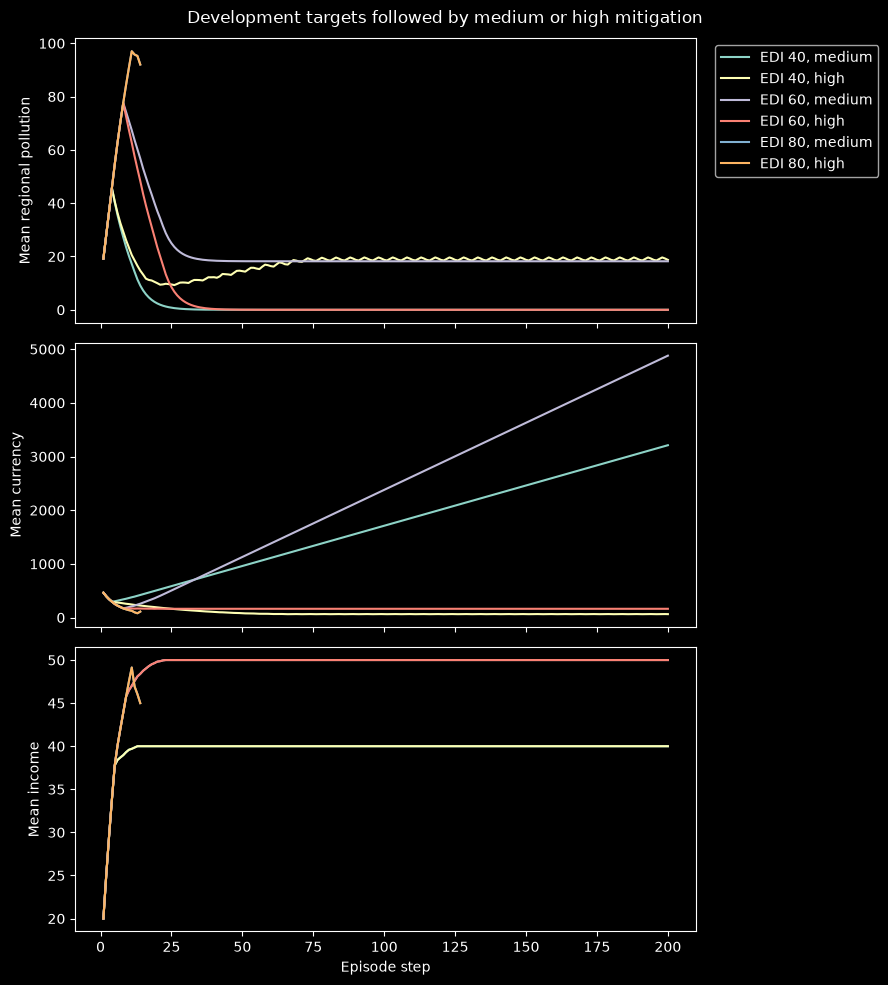

In [22]:
trace_frame = pd.DataFrame(baseline_trace)
trajectory_groups = trace_frame.groupby(["policy", "step"])[["pollution", "currency", "income", "spending"]].mean().reset_index()
fig, axes = plt.subplots(3, 1, figsize=(9, 10), sharex=True)
for target in TARGETS:
    for mode in ("medium", "high"):
        policy = f"target_{target}_{mode}"
        rows = trajectory_groups[trajectory_groups["policy"] == policy]
        axes[0].plot(rows["step"], rows["pollution"], label=f"EDI {target}, {mode}")
        axes[1].plot(rows["step"], rows["currency"], label=f"EDI {target}, {mode}")
        axes[2].plot(rows["step"], rows["income"], label=f"EDI {target}, {mode}")
axes[0].axhline(base_config.failure_threshold, color="black", linestyle="--")
axes[0].set_ylabel("Mean regional pollution")
axes[1].set_ylabel("Mean currency")
axes[2].set_ylabel("Mean income")
axes[2].set_xlabel("Episode step")
axes[0].legend(bbox_to_anchor=(1.02, 1), loc="upper left")
fig.suptitle("Development targets followed by medium or high mitigation")
plt.tight_layout()
plt.show()

## 5. High-mitigation capacity and price sensitivity

- Test every combination of high capacity 16, 20, or 30 and high cost 25 or 50.
- The four follow-up combinations are capacity 16 or 30 crossed with cost 25 or 50. They compare low and high capacity at both price levels.

In [15]:
def run_comparison_grid(persistence, capacity_cost_pairs, policies):
    rows = []
    for capacity, high_cost in capacity_cost_pairs:
        for policy in policies:
            for seed in SEEDS:
                row, trace = run_policy_episode(policy, seed, persistence=persistence, capacity=capacity, high_cost=high_cost)
                rows.append(row)
    return pd.DataFrame(rows)

ALL_CAPACITY_COST_PAIRS = []
for capacity in CAPACITIES:
    for cost in HIGH_COSTS:
        ALL_CAPACITY_COST_PAIRS.append((capacity, cost))
main_grid = run_comparison_grid(PERSISTENCE_BASELINE, ALL_CAPACITY_COST_PAIRS, POLICY_ORDER)
followup_pairs = []
for capacity in (16, 30):
    for cost in HIGH_COSTS:
        followup_pairs.append((capacity, cost))
followup_grid = run_comparison_grid(PERSISTENCE_FOLLOW_UP, followup_pairs, POLICY_ORDER)

failure_rate         steps         \
                                               mean   std    mean    std   
capacity high_cost policy                                                  
16       25        adaptive_after_67           0.68  0.47   72.76  87.74   
                   target_40_high              0.00  0.00  200.00   0.00   
                   target_40_medium            0.00  0.00  200.00   0.00   
                   target_60_high              0.01  0.10  198.14  18.60   
                   target_60_medium            0.01  0.10  198.14  18.60   
                   target_80_high              1.00  0.00   11.24   0.53   
                   target_80_medium            1.00  0.00   11.24   0.53   
                   threshold_reference         0.68  0.47   72.77  87.73   
         50        adaptive_after_67           0.68  0.47   72.76  87.74   
                   target_40_high              0.00  0.00  200.00   0.00   
                   target_40_medium            0.00  0.00  200.00   0.00   
                   target_60_high              0.01  0.10  198.14  18.60   
                   target_60_medium            0.01  0.10  198.14  18.60   
                   target_80_high              1.00  0.00   11.24   0.53   
                   target_80_medium            1.00  0.00   11.24   0.53   
                   threshold_reference         0.68  0.47   72.77  87.73   
20       25        adaptive_after_67           0.67  0.47   74.98  88.20   
                   target_40_high              0.00  0.00  200.00   0.00   
                   target_40_medium            0.00  0.00  200.00   0.00   
                   target_60_high              0.01  0.10  198.14  18.60   
                   target_60_medium            0.01  0.10  198.14  18.60   
                   target_80_high              1.00  0.00   11.24   0.53   
                   target_80_medium            1.00  0.00   11.24   0.53   
                   threshold_reference         0.63  0.49   82.45  90.56   
         50        adaptive_after_67           0.67  0.47   74.98  88.20   
                   target_40_high              0.00  0.00  200.00   0.00   
                   target_40_medium            0.00  0.00  200.00   0.00   
                   target_60_high              0.01  0.10  198.14  18.60   
                   target_60_medium            0.01  0.10  198.14  18.60   
                   target_80_high              1.00  0.00   11.24   0.53   
                   target_80_medium            1.00  0.00   11.24   0.53   
                   threshold_reference         0.63  0.49   82.45  90.56   
30       25        adaptive_after_67           0.67  0.47   74.98  88.20   
                   target_40_high              0.00  0.00  200.00   0.00   
                   target_40_medium            0.00  0.00  200.00   0.00   
                   target_60_high              0.01  0.10  198.14  18.60   
                   target_60_medium            0.01  0.10  198.14  18.60   
                   target_80_high              1.00  0.00   11.24   0.53   
                   target_80_medium            1.00  0.00   11.24   0.53   
                   threshold_reference         0.63  0.49   82.45  90.56   
         50        adaptive_after_67           0.67  0.47   74.98  88.20   
                   target_40_high              0.00  0.00  200.00   0.00   
                   target_40_medium            0.00  0.00  200.00   0.00   
                   target_60_high              0.01  0.10  198.14  18.60   
                   target_60_medium            0.01  0.10  198.14  18.60   
                   target_80_high              1.00  0.00   11.24   0.53   
                   target_80_medium            1.00  0.00   11.24   0.53   
                   threshold_reference         0.63  0.49   82.45  90.56   

                                       final_mean_edi       mean_pollution  \
                                                 mean   std           mean   
capaci

In [23]:
main_group_summary = summarize_episodes(main_grid, ["capacity", "high_cost", "policy"])
display(main_group_summary)

failure_rate         steps         \
                                               mean   std    mean    std   
capacity high_cost policy                                                  
16       25        adaptive_after_67           0.68  0.47   72.76  87.74   
                   target_40_high              0.00  0.00  200.00   0.00   
                   target_40_medium            0.00  0.00  200.00   0.00   
                   target_60_high              0.01  0.10  198.14  18.60   
                   target_60_medium            0.01  0.10  198.14  18.60   
                   target_80_high              1.00  0.00   11.24   0.53   
                   target_80_medium            1.00  0.00   11.24   0.53   
                   threshold_reference         0.68  0.47   72.77  87.73   
         50        adaptive_after_67           0.68  0.47   72.76  87.74   
                   target_40_high              0.00  0.00  200.00   0.00   
                   target_40_medium            0.00  0.00  200.00   0.00   
                   target_60_high              0.01  0.10  198.14  18.60   
                   target_60_medium            0.01  0.10  198.14  18.60   
                   target_80_high              1.00  0.00   11.24   0.53   
                   target_80_medium            1.00  0.00   11.24   0.53   
                   threshold_reference         0.68  0.47   72.77  87.73   
20       25        adaptive_after_67           0.67  0.47   74.98  88.20   
                   target_40_high              0.00  0.00  200.00   0.00   
                   target_40_medium            0.00  0.00  200.00   0.00   
                   target_60_high              0.01  0.10  198.14  18.60   
                   target_60_medium            0.01  0.10  198.14  18.60   
                   target_80_high              1.00  0.00   11.24   0.53   
                   target_80_medium            1.00  0.00   11.24   0.53   
                   threshold_reference         0.63  0.49   82.45  90.56   
         50        adaptive_after_67           0.67  0.47   74.98  88.20   
                   target_40_high              0.00  0.00  200.00   0.00   
                   target_40_medium            0.00  0.00  200.00   0.00   
                   target_60_high              0.01  0.10  198.14  18.60   
                   target_60_medium            0.01  0.10  198.14  18.60   
                   target_80_high              1.00  0.00   11.24   0.53   
                   target_80_medium            1.00  0.00   11.24   0.53   
                   threshold_reference         0.63  0.49   82.45  90.56   
30       25        adaptive_after_67           0.67  0.47   74.98  88.20   
                   target_40_high              0.00  0.00  200.00   0.00   
                   target_40_medium            0.00  0.00  200.00   0.00   
                   target_60_high              0.01  0.10  198.14  18.60   
                   target_60_medium            0.01  0.10  198.14  18.60   
                   target_80_high              1.00  0.00   11.24   0.53   
                   target_80_medium            1.00  0.00   11.24   0.53   
                   threshold_reference         0.63  0.49   82.45  90.56   
         50        adaptive_after_67           0.67  0.47   74.98  88.20   
                   target_40_high              0.00  0.00  200.00   0.00   
                   target_40_medium            0.00  0.00  200.00   0.00   
                   target_60_high              0.01  0.10  198.14  18.60   
                   target_60_medium            0.01  0.10  198.14  18.60   
                   target_80_high              1.00  0.00   11.24   0.53   
                   target_80_medium            1.00  0.00   11.24   0.53   
                   threshold_reference         0.63  0.49   82.45  90.56   

                                       final_mean_edi       mean_pollution  \
                                                 mean   std           mean   
capaci

- Compare high capacity at a fixed price to see the effect of mitigation strength. Compare prices at a fixed capacity to see the affordability effect. A difference that appears only when both change suggests an interaction.
- A high capacity is wasted when it exceeds gross emissions: avoided emissions cannot exceed gross emissions. The per-episode `emissions_prevented` and `remaining_emissions` metrics show the realized effect, while the EDI table below shows this limit mechanically.

In [24]:
followup_summary = summarize_episodes(followup_grid, ["persistence", "capacity", "high_cost", "policy"])
display(followup_summary)

failure_rate        steps  \
                                                           mean  std    mean   
persistence capacity high_cost policy                                          
0.9         16       25        adaptive_after_67           1.00  0.0    8.00   
                               target_40_high              0.00  0.0  200.00   
                               target_40_medium            0.00  0.0  200.00   
                               target_60_high              1.00  0.0    8.00   
                               target_60_medium            1.00  0.0    8.00   
                               target_80_high              1.00  0.0    8.00   
                               target_80_medium            1.00  0.0    8.00   
                               threshold_reference         1.00  0.0    8.00   
                     50        adaptive_after_67           1.00  0.0    8.00   
                               target_40_high              0.01  0.1  198.11   
                               target_40_medium            0.00  0.0  200.00   
                               target_60_high              1.00  0.0    8.00   
                               target_60_medium            1.00  0.0    8.00   
                               target_80_high              1.00  0.0    8.00   
                               target_80_medium            1.00  0.0    8.00   
                               threshold_reference         1.00  0.0    8.00   
            30       25        adaptive_after_67           1.00  0.0    8.00   
                               target_40_high              0.00  0.0  200.00   
                               target_40_medium            0.00  0.0  200.00   
                               target_60_high              1.00  0.0    8.00   
                               target_60_medium            1.00  0.0    8.00   
                               target_80_high              1.00  0.0    8.00   
                               target_80_medium            1.00  0.0    8.00   
                               threshold_reference         1.00  0.0    8.00   
                     50        adaptive_after_67           1.00  0.0    8.00   
                               target_40_high              0.01  0.1  198.11   
                               target_40_medium            0.00  0.0  200.00   
                               target_60_high              1.00  0.0    8.00   
                               target_60_medium            1.00  0.0    8.00   
                               target_80_high              1.00  0.0    8.00   
                               target_80_medium            1.00  0.0    8.00   
                               threshold_reference         1.00  0.0    8.00   

                                                         final_mean_edi        \
                                                     std           mean   std   
persistence capacity high_cost policy                                           
0.9         16       25        adaptive_after_67     0.0          51.51  4.95   
                               target_40_high        0.0          40.00  0.00   
                               target_40_medium      0.0          40.00  0.00   
                               target_60_high        0.0          51.51  4.95   
                               target_60_medium      0.0          51.51  4.95   
                               target_80_high        0.0          51.51  4.95   
                               target_80_medium      0.0          51.51  4.95   
                               threshold_reference   0.0          51.51  4.95   
                     50        adaptive_after_67     0.0          51.51  4.95   
                               target_40_high       18.9          39.98  0.25   
                               target_40_medium      0.0          40.00  0.00   
                               target_60_high        0.0          51.51  4.95   
                               targ

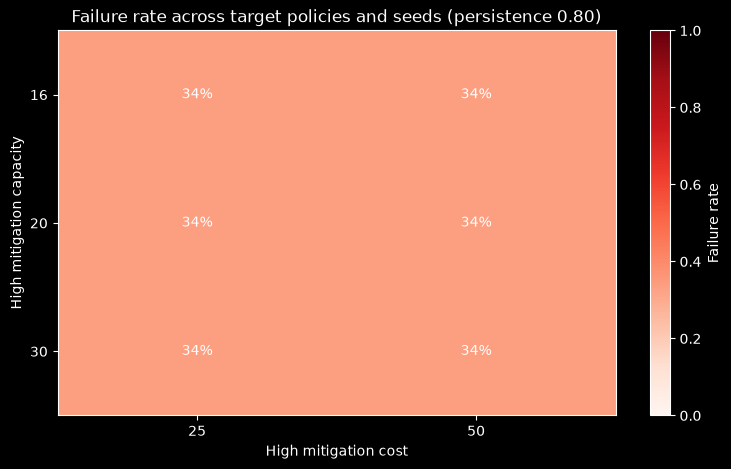

In [25]:
fig, ax = plt.subplots(figsize=(9, 5))
heat_data = main_grid[main_grid["policy"].str.startswith("target_")].groupby(["capacity", "high_cost"])["failed"].mean().unstack("high_cost")
image = ax.imshow(heat_data, vmin=0, vmax=1, cmap="Reds", aspect="auto")
ax.set_xticks(range(len(HIGH_COSTS)), HIGH_COSTS)
ax.set_yticks(range(len(CAPACITIES)), CAPACITIES)
ax.set(xlabel="High mitigation cost", ylabel="High mitigation capacity", title="Failure rate across target policies and seeds (persistence 0.80)")
for row_index in range(len(CAPACITIES)):
    for column_index in range(len(HIGH_COSTS)):
        ax.text(column_index, row_index, f"{heat_data.iloc[row_index, column_index]:.0%}", ha="center", va="center")
fig.colorbar(image, ax=ax, label="Failure rate")
plt.show()

## 6. Financial and mitigation effectiveness

In [26]:
action_columns = []
for kind in ("proposed", "executed"):
    for action in ACTION_NAMES:
        action_columns.append(f"{kind}_{action}_fraction")
action_summary = main_grid.groupby(["capacity", "high_cost", "policy"])[action_columns + ["fallback_count", "mitigation_attempts", "mitigation_executed"]].mean().round(3)
display(action_summary)

proposed_save_fraction  \
capacity high_cost policy                                        
16       25        adaptive_after_67                       0.0   
                   target_40_high                          0.0   
                   target_40_medium                        0.0   
                   target_60_high                          0.0   
                   target_60_medium                        0.0   
                   target_80_high                          0.0   
                   target_80_medium                        0.0   
                   threshold_reference                     0.0   
         50        adaptive_after_67                       0.0   
                   target_40_high                          0.0   
                   target_40_medium                        0.0   
                   target_60_high                          0.0   
                   target_60_medium                        0.0   
                   target_80_high                          0.0   
                   target_80_medium                        0.0   
                   threshold_reference                     0.0   
20       25        adaptive_after_67                       0.0   
                   target_40_high                          0.0   
                   target_40_medium                        0.0   
                   target_60_high                          0.0   
                   target_60_medium                        0.0   
                   target_80_high                          0.0   
                   target_80_medium                        0.0   
                   threshold_reference                     0.0   
         50        adaptive_after_67                       0.0   
                   target_40_high                          0.0   
                   target_40_medium                        0.0   
                   target_60_high                          0.0   
                   target_60_medium                        0.0   
                   target_80_high                          0.0   
                   target_80_medium                        0.0   
                   threshold_reference                     0.0   
30       25        adaptive_after_67                       0.0   
                   target_40_high                          0.0   
                   target_40_medium                        0.0   
                   target_60_high                          0.0   
                   target_60_medium                        0.0   
                   target_80_high                          0.0   
                   target_80_medium                        0.0   
                   threshold_reference                     0.0   
         50        adaptive_after_67                       0.0   
                   target_40_high                          0.0   
                   target_40_medium                        0.0   
                   target_60_high                          0.0   
                   target_60_medium                        0.0   
                   target_80_high                          0.0   
                   target_80_medium                        0.0   
                   threshold_reference                     0.0   

                                        proposed_develop_fraction  \
capacity high_cost policy                                           
16       25        adaptive_after_67                        0.658   
                   target_40_high                           0.025   
                   target_40_medium                         0.025   
                   target_60_high                           0.065   
                   target_60_medium                         0.065   
                   target_80_high                           1.000   
                   target_80_medium                         1.000   
                   threshold_reference                      0.658   
         50        adaptive_after_67             

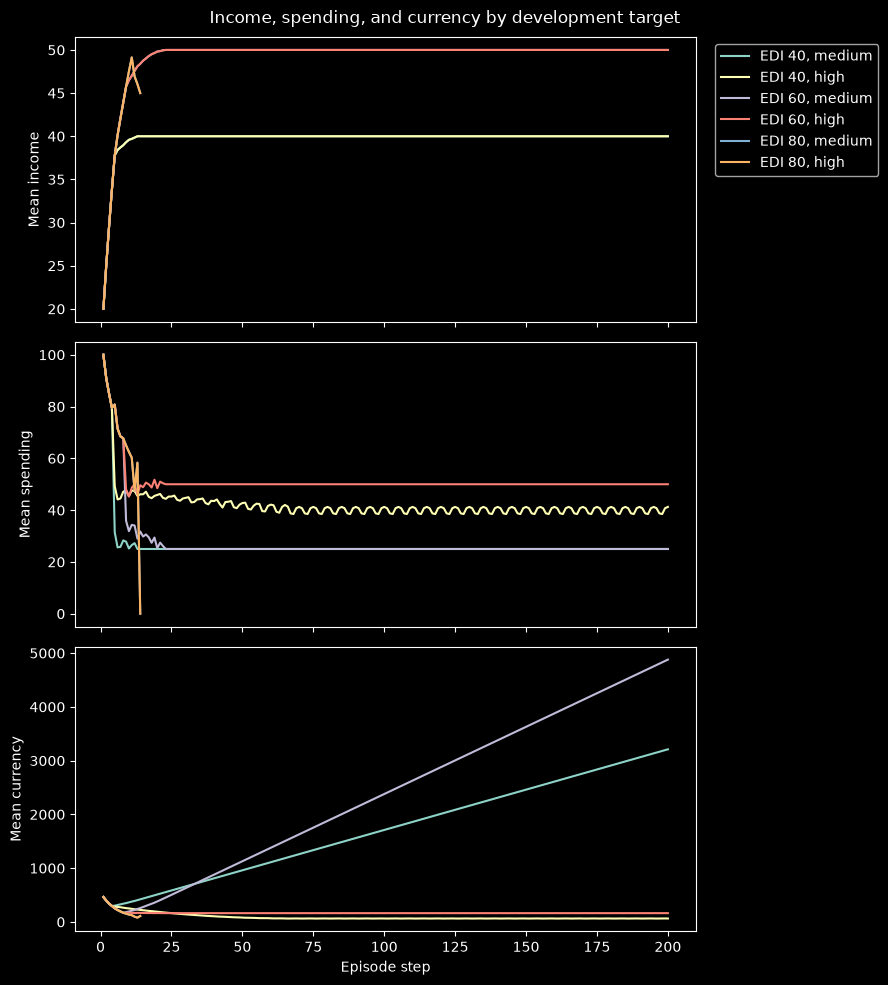

In [27]:
current_trace = pd.DataFrame(baseline_trace)
current_trace_summary = current_trace.groupby(["policy", "step"])[["income", "spending", "currency"]].mean().reset_index()
fig, axes = plt.subplots(3, 1, figsize=(9, 10), sharex=True)
for target in TARGETS:
    for mode in ("medium", "high"):
        policy = f"target_{target}_{mode}"
        rows = current_trace_summary[current_trace_summary["policy"] == policy]
        axes[0].plot(rows["step"], rows["income"], label=f"EDI {target}, {mode}")
        axes[1].plot(rows["step"], rows["spending"], label=f"EDI {target}, {mode}")
        axes[2].plot(rows["step"], rows["currency"], label=f"EDI {target}, {mode}")
axes[0].set_ylabel("Mean income")
axes[1].set_ylabel("Mean spending")
axes[2].set_ylabel("Mean currency")
axes[2].set_xlabel("Episode step")
axes[0].legend(bbox_to_anchor=(1.02, 1), loc="upper left")
fig.suptitle("Income, spending, and currency by development target")
plt.tight_layout()
plt.show()

In [28]:
edi_values = (0, 40, 60, 70, 80, 100)
capacity_rows = []
for capacity in CAPACITIES:
    for edi in edi_values:
        gross = base_config.emissions_base + base_config.emissions_edi_linear * edi + base_config.emissions_edi_quadratic * edi ** 2
        capacity_rows.append({"capacity": capacity, "edi": edi, "gross_emissions": gross, "emissions_prevented": min(gross, capacity), "remaining_emissions": max(0, gross - capacity)})
display(pd.DataFrame(capacity_rows).set_index(["capacity", "edi"]).round(2))

gross_emissions  emissions_prevented  remaining_emissions
capacity edi                                                           
16       0                8.0                  8.0                  0.0
         40              13.6                 13.6                  0.0
         60              17.6                 16.0                  1.6
         70              19.9                 16.0                  3.9
         80              22.4                 16.0                  6.4
         100             28.0                 16.0                 12.0
20       0                8.0                  8.0                  0.0
         40              13.6                 13.6                  0.0
         60              17.6                 17.6                  0.0
         70              19.9                 19.9                  0.0
         80              22.4                 20.0                  2.4
         100             28.0                 20.0                  8.0
30       0                8.0                  8.0                  0.0
         40              13.6                 13.6                  0.0
         60              17.6                 17.6                  0.0
         70              19.9                 19.9                  0.0
         80              22.4                 22.4                  0.0
         100             28.0                 28.0                  0.0

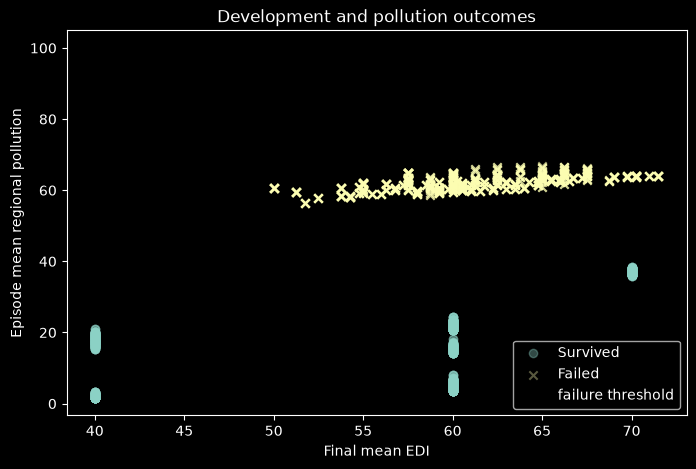

In [29]:
scatter = main_grid.copy()
fig, ax = plt.subplots(figsize=(8, 5))
for failed, label, marker in ((False, "Survived", "o"), (True, "Failed", "x")):
    rows = scatter[scatter["failed"] == failed]
    ax.scatter(rows["final_mean_edi"], rows["mean_pollution"], alpha=0.35, marker=marker, label=label)
ax.axhline(base_config.failure_threshold, color="black", linestyle="--", label="failure threshold")
ax.set(xlabel="Final mean EDI", ylabel="Episode mean regional pollution", title="Development and pollution outcomes")
ax.legend()
plt.show()

## Limitations and interpretation checklist

- These are deterministic hand-coded policies, not learned agents. The adaptive rule uses coarse observation bins and changes levels only when a bin changes.
- Failed episodes have shorter trajectories, so late-step averages include only episodes that survived that long.
- The pollution, income, cost, and capacity units remain synthetic. Results do not establish real-world calibration.
- Keep the reward design and environmental coefficients unchanged during this audit. Use the results to decide which settings deserve a later learned-agent comparison.